# AVIP 2026 — Task 1: Cats vs Dogs Image Classification

**Data:** TensorFlow Datasets `cats_vs_dogs` (Microsoft Research / Kaggle Dogs vs. Cats; approximately 23K usable images). TFDS handles known corrupted images. Dataset reference: https://www.tensorflow.org/datasets/catalog/cats_vs_dogs

**Method:** MobileNetV2 transfer learning, 70% training / 15% validation / 15% held-out test, fixed partitions, binary classification. Run this notebook top-to-bottom in **Google Colab** with a GPU runtime if possible.

In [2]:
!pip -q install tensorflow-datasets scikit-learn seaborn
%pip install -q importlib_resources

In [3]:
import os, json, random, pathlib
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
OUT = pathlib.Path('outputs'); OUT.mkdir(exist_ok=True)
IMG_SIZE = (160,160); BATCH_SIZE = 32

**Load and Split the Dataset**

The TFDS Cats vs Dogs dataset contains a single train split, which is divided into three non-overlapping sets: 70% training, 15% validation, and 15% testing. The splits remain the same across runs, and only the training set is shuffled during model training.

In [4]:
splits = ['train[:70%]', 'train[70%:85%]', 'train[85%:]']

(train_raw, val_raw, test_raw), info = tfds.load(
    'cats_vs_dogs',
    split=splits,
    as_supervised=True,
    with_info=True
)

class_names = info.features['label'].names

print('Classes:', class_names)
print('Dataset:', info.homepage)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.HBRPOI_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Classes: ['cat', 'dog']
Dataset: https://www.microsoft.com/en-us/download/details.aspx?id=54765


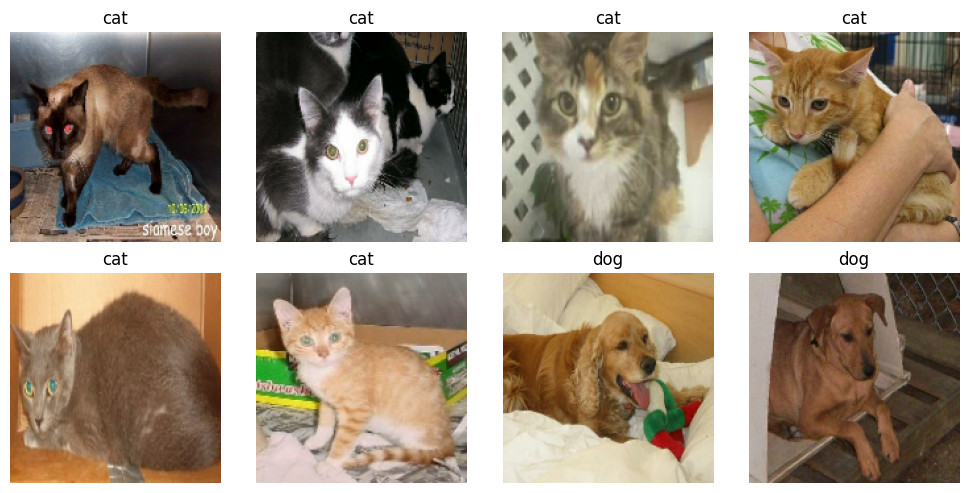

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

def preprocess(img, label):
    img = tf.image.resize(tf.cast(img, tf.float32), IMG_SIZE)
    return img, tf.cast(label, tf.float32)

train_ds = (train_raw.map(preprocess, num_parallel_calls=AUTOTUNE)
            .shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds = val_raw.map(preprocess, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = test_raw.map(preprocess, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

for imgs, labels in train_ds.take(1):
    fig, axes = plt.subplots(2,4,figsize=(10,5))
    for ax,img,label in zip(axes.flat,imgs[:8],labels[:8]):
        ax.imshow(tf.cast(img,tf.uint8)); ax.set_title(class_names[int(label)]); ax.axis('off')
    plt.tight_layout(); plt.show()

## Train the classifier

MobileNetV2 pretrained weights provide an efficient image feature extractor. Training augmentation is applied only to the training dataset inside the model, not to validation/test samples.

In [6]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
], name='train_augmentation')
base = tf.keras.applications.MobileNetV2(input_shape=(*IMG_SIZE,3), include_top=False, weights='imagenet')
base.trainable = False
inputs = tf.keras.Input(shape=(*IMG_SIZE,3))
x = augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)
model = tf.keras.Model(inputs,outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ train_augmentation (Sequential) │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/8
509/509 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.9519 - loss: 0.1241 - val_accuracy: 0.9791 - val_loss: 0.0534
Epoch 2/8
509/509 ━━━━━━━━━━━━━━━━━━━━ 34s 54ms/step - accuracy: 0.9670 - loss: 0.0834 - val_accuracy: 0.9808 - val_loss: 0.0501
Epoch 3/8
509/509 ━━━━━━━━━━━━━━━━━━━━ 30s 54ms/step - accuracy: 0.9701 - loss: 0.0781 - val_accuracy: 0.9828 - val_loss: 0.0490
Epoch 4/8
509/509 ━━━━━━━━━━━━━━━━━━━━ 30s 55ms/step - accuracy: 0.9698 - loss: 0.0779 - val_accuracy: 0.9822 - val_loss: 0.0466
Epoch 5/8
509/509 ━━━━━━━━━━━━━━━━━━━━ 30s 54ms/step - accuracy: 0.9712 - loss: 0.0751 - val_accuracy: 0.9828 - val_loss: 0.0462
Epoch 6/8
509/509 ━━━━━━━━━━━━━━━━━━━━ 30s 54ms/step - accuracy: 0.9732 - loss: 0.0710 - val_accuracy: 0.9831 - val_loss: 0.0464
Epoch 7/8
509/509 ━━━━━━━━━━━━━━━━━━━━ 29s 53ms/step - accuracy: 0.9717 - loss: 0.0730 - val_accuracy: 0.9831 - val_loss: 0.0477
Epoch 8/8
509/509 ━━━━━━━━━━━━━━━━━━━━ 30s 55ms/step - accuracy: 0.9724 - loss: 0.0739 - val_accu

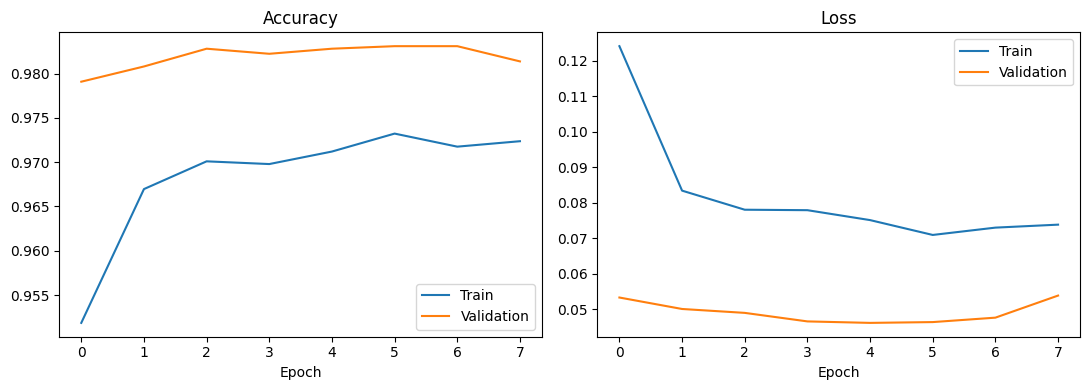

In [7]:
callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
             tf.keras.callbacks.ModelCheckpoint(str(OUT/'best_model.keras'), monitor='val_loss', save_best_only=True)]
history = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for metric,a in [('accuracy',ax[0]),('loss',ax[1])]:
    a.plot(history.history[metric],label='Train')
    a.plot(history.history['val_'+metric],label='Validation')
    a.set_title(metric.title());a.set_xlabel('Epoch');a.legend()
plt.tight_layout();plt.savefig(OUT/'training_curves.png',dpi=160);plt.show()

## Test-set evaluation

The trained model is evaluated on the **15% test dataset (3,489 images)**. Performance metrics and a confusion matrix are generated to measure classification accuracy. The results are saved in `metrics.json` and `confusion_matrix.png`. In the TFDS dataset, class `0` represents cat and class `1` represents dog.

110/110 ━━━━━━━━━━━━━━━━━━━━ 15s 114ms/step
{
  "accuracy": 0.9845227858985383,
  "precision_dog": 0.9863868406125922,
  "recall_dog": 0.9830412662521198,
  "f1_dog": 0.9847112117780294,
  "test_samples": 3489,
  "class_order": [
    "cat",
    "dog"
  ]
}
              precision    recall  f1-score   support

         cat       0.98      0.99      0.98      1720
         dog       0.99      0.98      0.98      1769

    accuracy                           0.98      3489
   macro avg       0.98      0.98      0.98      3489
weighted avg       0.98      0.98      0.98      3489



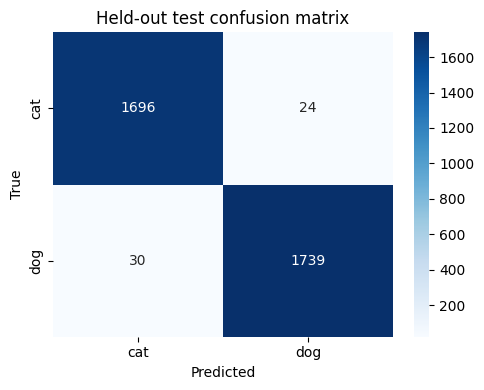

In [8]:
y_true = np.concatenate([y.numpy().astype(int) for _,y in test_ds])
y_prob = model.predict(test_ds, verbose=1).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)
precision, recall, f1, _ = precision_recall_fscore_support(y_true,y_pred,average='binary',zero_division=0)
metrics = {'accuracy':float(accuracy_score(y_true,y_pred)),
           'precision_dog':float(precision),'recall_dog':float(recall),
           'f1_dog':float(f1),'test_samples':int(len(y_true)), 'class_order':class_names}
print(json.dumps(metrics,indent=2))
print(classification_report(y_true,y_pred,target_names=class_names,zero_division=0))
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2))
cm = confusion_matrix(y_true,y_pred,labels=[0,1])
plt.figure(figsize=(5,4));sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',
  xticklabels=class_names,yticklabels=class_names)
plt.xlabel('Predicted');plt.ylabel('True');plt.title('Held-out test confusion matrix')
plt.tight_layout();plt.savefig(OUT/'confusion_matrix.png',dpi=180);plt.show()

## Ten test inference examples

All images below come from the held-out test partition. Each image shows its **ground-truth** and model **prediction**.

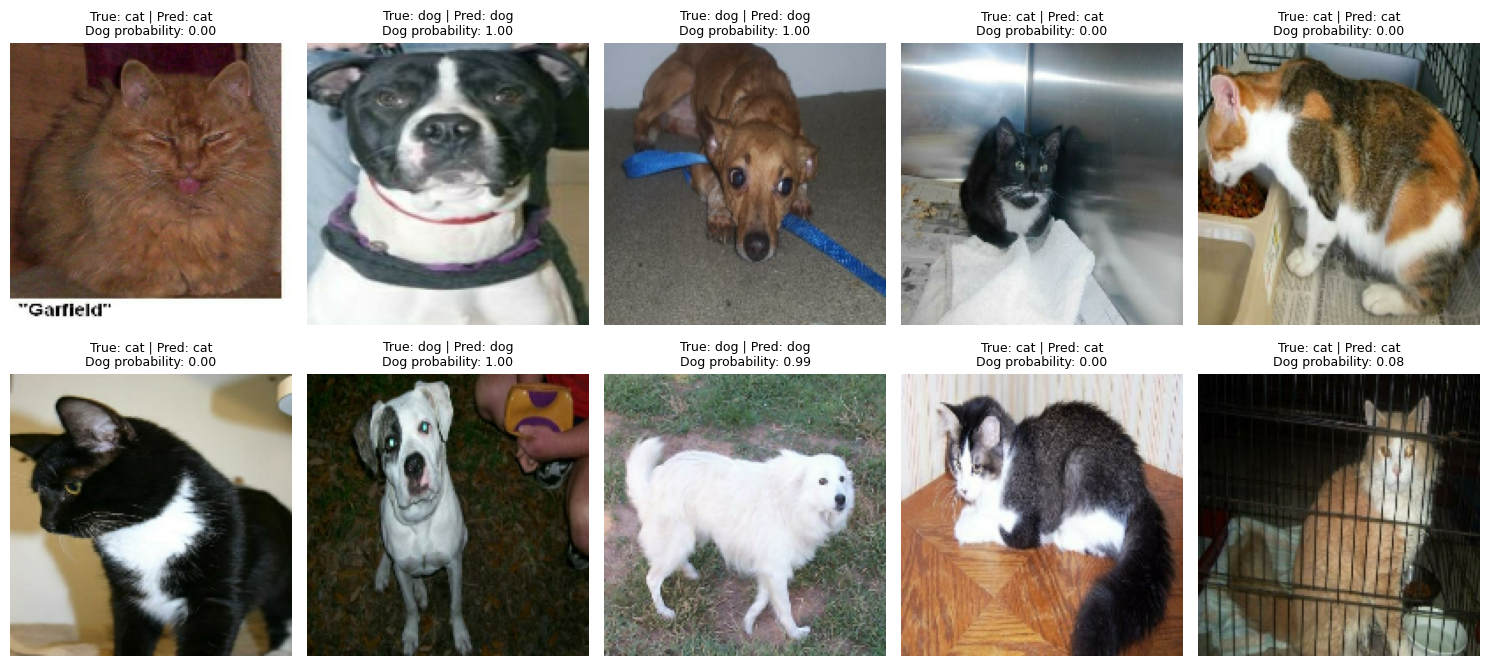

In [9]:
sample_images=[];sample_labels=[]
for batch_images,batch_labels in test_ds.take(1):
    sample_images=batch_images[:10].numpy()
    sample_labels=batch_labels[:10].numpy().astype(int)
example_probs=model.predict(sample_images,verbose=0).reshape(-1)
example_preds=(example_probs>=0.5).astype(int)
fig,axes=plt.subplots(2,5,figsize=(15,7))
for i,ax in enumerate(axes.flat):
    ax.imshow(sample_images[i].astype('uint8'))
    ax.set_title(f'True: {class_names[sample_labels[i]]} | Pred: {class_names[example_preds[i]]}\nDog probability: {example_probs[i]:.2f}',fontsize=9)
    ax.axis('off')
plt.tight_layout();plt.savefig(OUT/'10_test_predictions.png',dpi=170);plt.show()

## Save model and download deliverables

The best trained model is saved as `outputs/best_model.keras`. The saved model is loaded to verify that predictions work correctly. All output files, including the model, evaluation metrics, and plots, are compressed into a ZIP file for download.

In [10]:
best = tf.keras.models.load_model(OUT/'best_model.keras')
print('Best saved model loaded. Prediction shape:',best.predict(sample_images[:1],verbose=0).shape)
import shutil
shutil.make_archive('task1_outputs','zip',root_dir='.',base_dir='outputs')
print('Created task1_outputs.zip')

from google.colab import files
files.download('task1_outputs.zip')

Best saved model loaded. Prediction shape: (1, 1)
Created task1_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>